Example 3: Hybrid Bioreactor Estimation (Monod growth from Raman spectra)

A port of the standalone ``collocation_discopt.py`` / ``bioreactor_hybrid.py``
demos onto the ReactionModel API.

The setup: a batch culture (glucose -> biomass + lactate) watched by a Raman
probe. Two things make the raw spectra useless on their own:

- a large, drifting fluorescence envelope and a biomass-linked turbidity slope
  swamp the sharp Raman bands;
- glucose and lactate are given near-proportional spectra, so no amount of
  preprocessing can unmix them spectrally.

The fix is the same one KIPET rests on: put the mechanism in the model.
Second-derivative preprocessing kills the smooth baselines (a second difference
annihilates anything locally quadratic), classical least squares then recovers
noisy concentration trajectories, and ReactionModel fits the Monod ODE to those
by Radau collocation -- the states and the parameters are solved for together in
one NLP, with no time integration in the fit.

``mu_max`` comes out to a few percent. ``Ks`` does not, and that is a real
result rather than a tuning failure: ``Ks`` only acts where ``S ~ Ks``, and this
single batch spends almost no time there. A designed experiment or a prior is
the honest remedy.

Two costs of the CLS front end are worth seeing plainly. The second difference
amplifies noise more than signal here (``|d2(noise)|`` exceeds ``|d2(raman)|``
pointwise), and it leaves a small biased residual of the fluorescence curvature,
which pulls the early-time biomass low. Because growth scales with ``X``, that
bias inflates ``mu_max`` by a few percent. Fitting the mechanism straight to the
derivative spectra -- concentrating out the spectra rather than committing to a
CLS point estimate -- avoids both, but needs a spectral fit that permits SIGNED
pure-component spectra; kipetax currently constrains ``S_matrix >= 0``.

NOTE: all data here is SYNTHETIC, generated by the model below. The numbers are
chosen to be qualitatively like a real culture; they are not measured.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_3_bioreactor_monod.py`).

In [2]:
import numpy as np
import pandas as pd

from kipetax import ReactionModel

# ── True system (what we will try to recover) ──
MU_MAX, KS = 0.35, 0.6      # Monod growth parameters
YXS, YLS = 0.5, 0.8         # yield coefficients (held known)
X0, S0, L0 = 0.10, 10.0, 0.0

NU = np.linspace(800.0, 1800.0, 500)   # wavenumber grid, cm^-1
T = np.linspace(0.0, 24.0, 40)         # sampling times, hours

def lorentzian(nu, center, width, amp):
    return amp / (1.0 + ((nu - center) / width) ** 2)

def s_glucose(nu):
    return (lorentzian(nu, 1060, 18, 1.00) + lorentzian(nu, 1130, 20, 0.60)
            + lorentzian(nu, 1365, 18, 0.35))

def s_lactate(nu):
    # near-proportional to glucose: the "inseparable metabolites" case
    return (lorentzian(nu, 1060, 18, 0.85) + lorentzian(nu, 1130, 20, 0.72)
            + lorentzian(nu, 1365, 18, 0.28))

def s_biomass(nu):
    return (lorentzian(nu, 1003, 10, 0.5) + lorentzian(nu, 1450, 22, 0.6)
            + lorentzian(nu, 1660, 26, 0.7))

def bg_fluor(nu):
    return np.exp(-((nu - 1300.0) ** 2) / (2 * 600.0 ** 2))

def bg_turbidity(nu):
    x = (nu - nu[0]) / (nu[-1] - nu[0])
    return 1.0 - 0.7 * x

def true_states():
    """Reference Monod trajectories by dense RK4 (data generation only)."""
    def f(y):
        X, S, L = y
        S = max(S, 0.0)
        growth = (MU_MAX * S / (KS + S)) * X
        return np.array([growth, -growth / YXS, YLS * growth / YXS])

    substeps = 8
    h = (T[1] - T[0]) / substeps
    y = np.array([X0, S0, L0])
    out = [y.copy()]
    for _ in range(len(T) - 1):
        for _ in range(substeps):
            k1 = f(y)
            k2 = f(y + 0.5 * h * k1)
            k3 = f(y + 0.5 * h * k2)
            k4 = f(y + h * k3)
            y = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        out.append(y.copy())
    Y = np.array(out)
    return Y[:, 0], Y[:, 1], Y[:, 2]

def build_measurement(seed=3):
    """Synthetic Raman D-matrix: bilinear bands + fluorescence + turbidity."""
    X, S, L = true_states()
    Sglu, Slac, Sbio = s_glucose(NU), s_lactate(NU), s_biomass(NU)

    raman = np.outer(S, Sglu) + np.outer(L, Slac) + np.outer(X, Sbio)

    fluor_t = 6.0 * (0.3 + X / X.max())      # dwarfs the sharp bands
    turb_t = 1.5 * X
    background = np.outer(fluor_t, bg_fluor(NU)) + np.outer(turb_t, bg_turbidity(NU))

    rng = np.random.default_rng(seed)
    noise = 8e-3 * rng.standard_normal(raman.shape)

    return raman + background + noise, (X, S, L), (Sglu, Slac, Sbio)

def d2(A):
    """Second difference along the wavenumber axis: annihilates smooth baselines."""
    return A[..., 2:] - 2 * A[..., 1:-1] + A[..., :-2]

def cls_concentrations(D, pure):
    """Classical least squares on 2nd-derivative spectra -> concentrations."""
    Sglu, Slac, Sbio = pure
    A = np.column_stack([d2(Sglu), d2(Slac), d2(Sbio)])    # (n_nu-2, 3)
    C, *_ = np.linalg.lstsq(A, d2(D).T, rcond=None)         # (3, n_times)
    S_hat, L_hat, X_hat = C
    return pd.DataFrame({'X': X_hat, 'S': S_hat, 'L': L_hat}, index=T)

## Run the analysis

In [3]:
D, (X_true, S_true, L_true), pure = build_measurement()

In [4]:
# Front end: derivative preprocessing + CLS. The baselines are gone, but the
# glucose/lactate split is still near-singular -- the mechanism resolves it.
df = cls_concentrations(D, pure)
print(f"CLS front end: {df.shape[0]} points, {df.shape[1]} states")

CLS front end: 40 points, 3 states


In [5]:
# Back end: the Monod mechanism, fit by collocation.
r1 = ReactionModel('bioreactor_monod')

In [6]:
mu_max = r1.parameter('mu_max', value=0.20, bounds=(0.05, 1.0))
ks = r1.parameter('ks', value=1.0, bounds=(0.01, 5.0))

In [7]:
Yxs = r1.constant('Yxs', value=YXS)
Yls = r1.constant('Yls', value=YLS)

In [8]:
X = r1.component('X', value=X0)
S = r1.component('S', value=S0)
L = r1.component('L', value=L0)

In [9]:
growth = mu_max * S / (ks + S) * X
r1.add_ode('X', growth)
r1.add_ode('S', -growth / Yxs)
r1.add_ode('L', Yls * growth / Yxs)

PendingBinaryOp('/', PendingBinaryOp('*', KipetProxy('Yls', 'constant'), PendingBinaryOp('*', PendingBinaryOp('/', PendingBinaryOp('*', KipetProxy('mu_max', 'parameter'), KipetProxy('S', 'component')), PendingBinaryOp('+', KipetProxy('ks', 'parameter'), KipetProxy('S', 'component'))), KipetProxy('X', 'component'))), KipetProxy('Yxs', 'constant'))

In [10]:
r1.add_data(name='cls_concentrations', data=df)
r1.set_discretization(nfe=16, ncp=3)

In [11]:
print("\nRunning parameter estimation (Radau collocation + POUNCE)...")
r1.run_opt(variances={'X': 1e-3, 'S': 1e-2, 'L': 1e-2}, covariance=True)


Running parameter estimation (Radau collocation + POUNCE)...


Parameter estimation complete: status=optimal
  mu_max               = 0.370956
  ks                   = 1.10186


In [12]:
ro = r1.results_dict['p_estimator']

In [13]:
print(f"\nStatus: {ro.status}   objective: {ro.objective:.6e}")
print(f"\n  {'Parameter':10s} {'True':>10s} {'Estimated':>12s} {'Error%':>10s}")
print(f"  {'-' * 46}")
for name, truth in [('mu_max', MU_MAX), ('ks', KS)]:
    est = ro.P.get(name, float('nan'))
    err = abs(est - truth) / truth * 100
    print(f"  {name:10s} {truth:>10.4f} {est:>12.4f} {err:>9.2f}%")


Status: optimal   objective: 1.361300e+02

  Parameter        True    Estimated     Error%
  ----------------------------------------------
  mu_max         0.3500       0.3710      5.99%
  ks             0.6000       1.1019     83.64%


In [14]:
if ro.confidence_intervals:
    print("\n95% confidence intervals (see caveat below):")
    for name, (lo, hi) in ro.confidence_intervals.items():
        print(f"  {name:10s} [{lo:>9.4f}, {hi:>9.4f}]")
    print("  CAVEAT: these assume independent errors on the CLS-derived\n"
          "  concentrations. They are not independent -- the second difference\n"
          "  correlates adjacent wavenumbers and leaves a small biased residual\n"
          "  of the fluorescence curvature. The intervals are therefore\n"
          "  optimistic and need not cover the true values.")


95% confidence intervals (see caveat below):
  mu_max     [   0.3647,    0.3772]
  ks         [   0.9588,    1.2449]
  CAVEAT: these assume independent errors on the CLS-derived
  concentrations. They are not independent -- the second difference
  correlates adjacent wavenumbers and leaves a small biased residual
  of the fluorescence curvature. The intervals are therefore
  optimistic and need not cover the true values.


In [15]:
# Trajectory quality against the true (noise-free) states
Z = ro.Z
for name, truth in [('X', X_true), ('S', S_true), ('L', L_true)]:
    pred = np.interp(T, Z.index.values, Z[name].values)
    scale = max(np.ptp(truth), 1e-12)
    rmse = np.sqrt(np.mean((pred - truth) ** 2)) / scale
    print(f"  {name} trajectory NRMSE: {rmse * 100:.2f}%")

  X trajectory NRMSE: 0.68%
  S trajectory NRMSE: 0.68%
  L trajectory NRMSE: 0.68%


In [16]:
ro

ResultsObject(status='optimal', objective=136.13002810333876, params=[mu_max=0.370956, ks=1.10186])

## Visualization

Persistent figures: raw Raman (background-dominated), the CLS vs mechanism vs true trajectories, the Monod-curve identifiability of Ks, and parameter recovery.

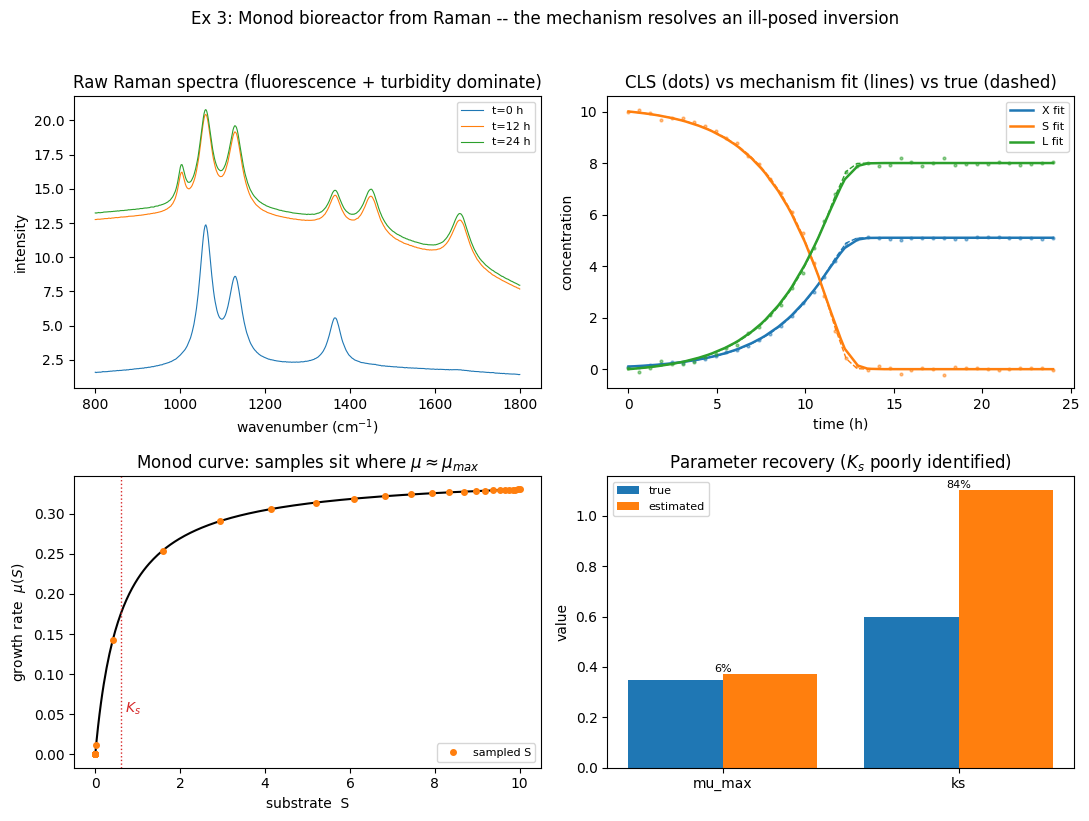

In [17]:
import matplotlib.pyplot as plt

Z = ro.Z

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) Raw Raman: a drifting fluorescence envelope + turbidity swamp the bands.
for i in (0, len(T) // 2, len(T) - 1):
    ax[0, 0].plot(NU, D[i], lw=0.8, label=f't={T[i]:.0f} h')
ax[0, 0].set(title='Raw Raman spectra (fluorescence + turbidity dominate)',
             xlabel='wavenumber (cm$^{-1}$)', ylabel='intensity')
ax[0, 0].legend(fontsize=8)

# (b) CLS front end (dots) vs mechanism fit (lines) vs true (dashed).
colors = {'X': 'C0', 'S': 'C1', 'L': 'C2'}
for name, truth in [('X', X_true), ('S', S_true), ('L', L_true)]:
    c = colors[name]
    ax[0, 1].plot(T, df[name], ls='', marker='.', ms=4, color=c, alpha=0.5)
    ax[0, 1].plot(Z.index, Z[name], '-', color=c, lw=1.8, label=f'{name} fit')
    ax[0, 1].plot(T, truth, '--', color=c, lw=1.0)
ax[0, 1].set(title='CLS (dots) vs mechanism fit (lines) vs true (dashed)',
             xlabel='time (h)', ylabel='concentration')
ax[0, 1].legend(fontsize=8)

# (c) Why Ks is poorly identified: the batch barely visits S ~ Ks.
Sgrid = np.linspace(0.0, S_true.max(), 300)
ax[1, 0].plot(Sgrid, MU_MAX * Sgrid / (KS + Sgrid), 'k-', lw=1.5)
ax[1, 0].plot(S_true, MU_MAX * S_true / (KS + S_true), 'o', ms=4, color='C1',
              label='sampled S')
ax[1, 0].axvline(KS, color='C3', ls=':', lw=1)
ax[1, 0].text(KS * 1.15, MU_MAX * 0.15, '$K_s$', color='C3', fontsize=10)
ax[1, 0].set(title=r'Monod curve: samples sit where $\mu\approx\mu_{max}$',
             xlabel='substrate  S', ylabel=r'growth rate  $\mu(S)$')
ax[1, 0].legend(fontsize=8)

# (d) Parameter recovery: mu_max within a few %, Ks poorly identified.
names, tv = ['mu_max', 'ks'], [MU_MAX, KS]
ev = [ro.P['mu_max'], ro.P['ks']]
x = np.arange(len(names))
ax[1, 1].bar(x - 0.2, tv, 0.4, label='true')
ax[1, 1].bar(x + 0.2, ev, 0.4, label='estimated')
for xi, (t, e) in enumerate(zip(tv, ev)):
    ax[1, 1].annotate(f'{abs(e - t) / t * 100:.0f}%', (xi, max(t, e)),
                      ha='center', va='bottom', fontsize=8)
ax[1, 1].set_xticks(x)
ax[1, 1].set_xticklabels(names)
ax[1, 1].set(title='Parameter recovery ($K_s$ poorly identified)', ylabel='value')
ax[1, 1].legend(fontsize=8)

fig.suptitle('Ex 3: Monod bioreactor from Raman -- the mechanism resolves an '
             'ill-posed inversion', y=1.02)
fig.tight_layout()